In [1]:
'''
yfinance -> online data
pandas -> offline data
matplotlib -> graphical representaion
statsmodel -> complex math made easy

'''

'\nyfinance -> online data\npandas -> offline data\nmatplotlib -> graphical representaion\nstatsmodel -> complex math made easy\n\n'

In [2]:
import yfinance as yf
import numpy as np
import statsmodels.api as sm
import statsmodels.tsa.stattools as ts
from statsmodels.tsa.stattools import coint

import pandas as pd
import matplotlib.pyplot as plt

In [3]:
ticker_1 = 'ICICIBANK'            #higher price
ticker_2 = 'HDFCBANK'           #lower price

start_date = '2026-01-01'
end_date = '2026-10-01'

In [4]:
#Creating a data frame to access and perform operations ,  MOST IMPORTANTLY DATES ALLIGN THE PRICES FOR THAT DAY
close = yf.download([ticker_1 + '.NS', ticker_2 + '.NS'], start_date, end_date)['Close']

y = close[ticker_1 + '.NS']
x = close[ticker_2 + '.NS']

[*********************100%***********************]  1 of 2 completed


In [5]:
constant = sm.add_constant(x)     #add constant/intercept so the line don't pass through origin
model = sm.OLS(y, constant).fit() #performing ols fit

#y = c + mx

#beta = model.params[ticker_2 + '.NS']

beta = model.params.iloc[1]
constt = model.params['const']  #generic name is const, can get it using params.iloc[0] as it's at first position

In [6]:
print(beta)
print(constt)

0.1737990890120377
1207.0962280090716


In [7]:
#graph

In [8]:
#spread = y - (beta*x + constt), though cosntt can be ignored when we use z-score method to trtade

spread = model.resid   #will not be using it as it is ideal, CADF will be stricter and less prone to error for ols data

# CADF

In [9]:
#for backtest -> strciter means to find cointegration as ols made the spread iedal stationary time series
#penalize with MacKinnon Critical Values

coint_t, p_value, crit_value = coint(y, x)  

print(p_value)

0.6673370337697753


In [10]:
#for live trading we use previously calculated beta and direct dicker-fuller test

spread = y - (beta*x + constt)  #live

adf = ts.adfuller(spread)      #for predefined beta and constant

print(adf[1])

0.4226988761382761


/tmp/ipykernel_8467/1591578172.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = ts.adfuller(spread)      #for predefined beta and constant


# HALF LIFE

In [11]:
prev = spread.shift(1)   # y t-1
diff = spread - prev     # del y

prev = prev.dropna()    #NaN first row removal
diff = diff.dropna()

#to get psi or lamda slope of df equation

konst = sm.add_constant(prev)
modl = sm.OLS(diff, konst).fit()

lam = modl.params.iloc[1]    #value of slope 

half_life = -np.log(2)/lam

print(half_life)      #ideal: 5-30 days

22.78517195102121


# Z-SCORE

In [12]:
lookback = 20
roll_mean = spread.rolling(window = lookback).mean()
roll_std = spread.rolling(window = lookback).std()

z_score = (spread - roll_mean)/roll_std
z_score = z_score.dropna()

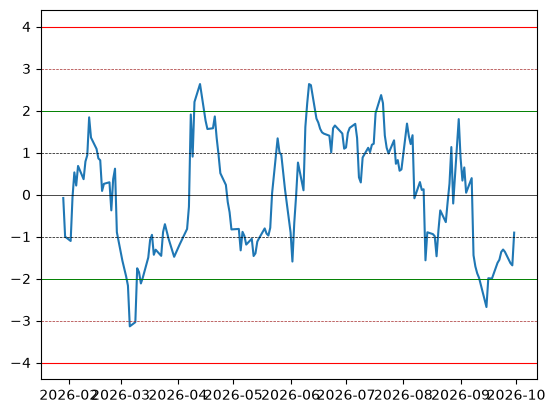

In [29]:
plt.plot(z_score.index, z_score)
plt.axhline(0, color='black', linewidth=0.5)
plt.axhline(1, color='black', linestyle='--', linewidth=0.5)
plt.axhline(-1, color='black', linestyle='--', linewidth=0.5)
plt.axhline(2, color='green', linewidth=0.7)
plt.axhline(-2, color='green', linewidth=0.7)
plt.axhline(3, color='brown', linestyle='--', linewidth=0.5)
plt.axhline(-3, color='brown', linestyle='--', linewidth=0.5)
plt.axhline(4, color='red', linewidth=0.8)
plt.axhline(-4, color='red', linewidth=0.8)

In [3]:
import yfinance as yf
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.tsa.stattools as ts
from statsmodels.tsa.stattools import coint
from datetime import datetime, timedelta

# 1. RELATIVE DATE WINDOW (Rolling 1-Year / ~252 Trading Days)
end_date = datetime.today()
start_date = end_date - timedelta(days=365)

# 2. DEFINE SECTOR-PAIRED CANDIDATES ON NSE
candidate_pairs = [
    # --- Mid-Cap IT & ER&D (Tighter correlation than Large-Cap IT) ---
    ('LTIM', 'MPHASIS'),
    ('LTIM', 'PERSISTENT'),
    ('MPHASIS', 'COFORGE'),
    ('PERSISTENT', 'COFORGE'),
    ('LTTS', 'KPITTECH'),
    ('LTTS', 'TATAELXSI'),
    ('KPITTECH', 'TATAELXSI'),
    ('CYIENT', 'BIRLASOFT'),
    ('ZENSARTECH', 'SONATSOFTW'),

    # --- Pharmaceuticals (US Generics & Domestic Formulations) ---
    ('SUNPHARMA', 'CIPLA'),
    ('SUNPHARMA', 'DRREDDY'),
    ('CIPLA', 'DRREDDY'),
    ('LUPIN', 'AUROPHARMA'),
    ('LUPIN', 'TORNTPHARM'),
    ('DIVISLAB', 'LAURUSLABS'),
    ('ALKEM', 'GLENMARK'),
    ('BIOCON', 'ZYDUSLIFE'),

    # --- NBFCs, Housing & Gold Finance ---
    ('BAJFINANCE', 'CHOLAFIN'),
    ('CHOLAFIN', 'SHRIRAMFIN'),
    ('MUTHOOTFIN', 'MANAPPURAM'),
    ('LICHSGFIN', 'CANFINHOME'),
    ('PFC', 'RECLTD'),
    ('M&MFIN', 'SUNDARMFIN'),
    ('BAJFINANCE', 'BAJAJFINSV'),

    # --- Life & General Insurance + Asset Management ---
    ('SBILIFE', 'HDFCLIFE'),
    ('HDFCLIFE', 'ICICIPRULI'),
    ('SBILIFE', 'ICICIPRULI'),
    ('HDFCAMC', 'NAM-INDIA'),
    ('HDFCAMC', 'UTIAMC'),

    # --- Auto Ancillaries & Tire Manufacturers (Rubber/Crude linked) ---
    ('MRF', 'APOLLOTYRE'),
    ('APOLLOTYRE', 'CEATLTD'),
    ('APOLLOTYRE', 'JKTYRE'),
    ('CEATLTD', 'JKTYRE'),
    ('EXIDEIND', 'ARE&M'),
    ('BOSCHLTD', 'MOTHERSON'),
    ('BHARATFORG', 'SONACOMS'),

    # --- Private & Mid-Tier PSU Banks (Not in previous batch) ---
    ('AXISBANK', 'KOTAKBANK'),
    ('INDUSINDBK', 'FEDERALBNK'),
    ('FEDERALBNK', 'IDFCFIRSTB'),
    ('FEDERALBNK', 'KARURVYSYA'),
    ('CANBK', 'UNIONBANK'),
    ('UNIONBANK', 'INDIANB'),
    ('CANBK', 'INDIANB'),

    # --- Power Utilities, Gas & Energy ---
    ('NTPC', 'TATAPOWER'),
    ('TATAPOWER', 'JSWENERGY'),
    ('POWERGRID', 'NTPC'),
    ('IGL', 'MGL'),
    ('IGL', 'GUJGASLTD'),
    ('PETRONET', 'GAIL'),
    ('ONGC', 'OIL'),

    # --- Metals, Mining & Non-Ferrous ---
    ('HINDALCO', 'NATIONALUM'),
    ('JINDALSTEL', 'SAIL'),
    ('TATASTEEL', 'JINDALSTEL'),
    ('VEDL', 'HINDZINC'),
    ('NMDC', 'COALINDIA'),

    # --- Specialty Chemicals & Agrochemicals ---
    ('PIDILITIND', 'ASIANPAINT'),
    ('ASIANPAINT', 'BERGEPAINT'),
    ('BERGEPAINT', 'KANSAINER'),
    ('SRF', 'NAVINFLUOR'),
    ('UPL', 'PIIND'),
    ('DEEPAKNTR', 'AARTIIND'),

    # --- Cement (Mid-Cap & Regional) ---
    ('SHREECEM', 'DALBHARAT'),
    ('DALBHARAT', 'RAMCOCEM'),
    ('ACC', 'AMBUJACEM'),
    ('JKCEMENT', 'BIRLACORPN'),

    # --- PSU Defence, Railways & Capital Goods ---
    ('HAL', 'BEL'),
    ('BEL', 'BDL'),
    ('IRCTC', 'IRFC'),
    ('RVNL', 'IRCON'),
    ('SIEMENS', 'ABB'),
    ('CUMMINSIND', 'THERMAX'),

    # --- Real Estate (Interest Rate Sensitive) ---
    ('DLF', 'GODREJPROP'),
    ('GODREJPROP', 'OBEROIRLTY'),
    ('OBEROIRLTY', 'PRESTIGE')
]

# Extract unique tickers and download aligned close prices in a single batch
unique_tickers = list(set([t + '.NS' for pair in candidate_pairs for t in pair]))
print(f"Fetching NSE data from {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}...")

raw_data = yf.download(unique_tickers, start=start_date, end=end_date, progress=False)['Close']
raw_data = raw_data.dropna(how='all')

results = []

for t1, t2 in candidate_pairs:
    s1, s2 = t1 + '.NS', t2 + '.NS'
    
    # Align dates for the specific pair and drop missing rows
    df_pair = raw_data[[s1, s2]].dropna()
    if len(df_pair) < 150:
        continue

    # Ensure ticker_1 is the higher-priced stock on average (per your convention)
    if df_pair[s1].mean() >= df_pair[s2].mean():
        y, x = df_pair[s1], df_pair[s2]
        high_ticker, low_ticker = t1, t2
    else:
        y, x = df_pair[s2], df_pair[s1]
        high_ticker, low_ticker = t2, t1

    # 3. OLS HEDGE RATIO & SPREAD
    x_const = sm.add_constant(x)
    model = sm.OLS(y, x_const).fit()
    constt = model.params['const']
    beta = model.params.iloc[1]
    spread = y - (beta * x + constt)

    # 4. ENGLE-GRANGER COINTEGRATION & ADF TEST
    coint_t, p_val, crit_vals = coint(y, x)
    crit_5pct = crit_vals[1]  # 1% is [0], 5% is [1], 10% is [2]
    adf_stat, adf_pval, _, _, adf_crits, _ = ts.adfuller(spread)

    # 5. ORNSTEIN-UHLENBECK HALF-LIFE CALCULATION
    prev_spread = spread.shift(1).dropna()
    diff_spread = (spread - spread.shift(1)).dropna()
    
    ou_x = sm.add_constant(prev_spread)
    ou_model = sm.OLS(diff_spread, ou_x).fit()
    lam = ou_model.params.iloc[1]
    
    # Only valid mean reversion if lambda < 0
    half_life = -np.log(2) / lam if lam < 0 else np.nan

    # Filter for < 5% critical value (p_val < 0.05 and coint_t < 5% critical value)
    is_cointegrated = (p_val < 0.05) and (coint_t < crit_5pct)

    results.append({
        'Pair (Y / X)': f"{high_ticker} / {low_ticker}",
        'Hedge Ratio (Beta)': round(beta, 4),
        'Intercept': round(constt, 2),
        'Coint t-stat': round(coint_t, 3),
        '5% Crit Value': round(crit_5pct, 3),
        'Coint p-val': round(p_val, 4),
        'ADF p-val': round(adf_pval, 4),
        'Half-Life (Days)': round(half_life, 1) if not np.isnan(half_life) else np.inf,
        'Pass (<5% Crit)': is_cointegrated
    })

# Convert to DataFrame and sort by Cointegration p-value
results_df = pd.DataFrame(results).sort_values(by='Coint p-val')

# Display pairs that strictly pass the 5% critical threshold
cointegrated_df = results_df[results_df['Pass (<5% Crit)'] == True]

print("\n=== COINTEGRATED NSE PAIRS (p-value < 0.05 & t-stat < 5% Critical Value) ===")
if not cointegrated_df.empty:
    print(cointegrated_df.to_string(index=False))
else:
    print("No pairs passed the strict 5% Engle-Granger threshold in this exact window. Showing top 5 closest candidates:")
    print(results_df.head(5).to_string(index=False))

Fetching NSE data from 2025-10-22 to 2026-10-22...


$GUJGASLTD.NS: possibly delisted; no timezone found
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: BIRLASOFT.NS"}}}
$BIRLASOFT.NS: possibly delisted; no timezone found
$LTIM.NS: possibly delisted; no timezone found

3 Failed downloads:
['GUJGASLTD.NS', 'BIRLASOFT.NS', 'LTIM.NS']: possibly delisted; no timezone found



=== COINTEGRATED NSE PAIRS (p-value < 0.05 & t-stat < 5% Critical Value) ===
           Pair (Y / X)  Hedge Ratio (Beta)  Intercept  Coint t-stat  5% Crit Value  Coint p-val  ADF p-val  Half-Life (Days)  Pass (<5% Crit)
   CEATLTD / APOLLOTYRE              5.2590    1216.27        -5.055         -3.361       0.0001     0.0000               3.9             True
   SBILIFE / ICICIPRULI              1.6166     987.51        -4.787         -3.361       0.0004     0.0001               4.1             True
  JKCEMENT / BIRLACORPN              2.3875    3108.76        -4.358         -3.361       0.0021     0.0004               5.1             True
  CHOLAFIN / BAJFINANCE              1.5732     137.95        -4.293         -3.361       0.0026     0.0010               5.6             True
   CUMMINSIND / THERMAX              0.7041    2305.49        -4.234         -3.361       0.0032     0.0006               5.7             True
       CEATLTD / JKTYRE              3.0011    2303.25        -4